# Specifications, schema and JSON roundtrips

Build a validated input, inspect its schema and preserve its physical identity across serialization.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW.

## Understanding the API in this lesson

`BuildingBuilder` applies caller-supplied assumptions and observed replacements to construct a validated building. `BuildingSpec.model_dump_json()` serializes it; `model_validate_json()` reconstructs and validates it. `model_json_schema()` describes the accepted structure for other software.

The workflow figure identifies the full-building boundary this notebook exercises. Validation checks the input contract. Compilation adds emitted-surface and engine-schema checks, while a run adds engine/output acceptance. These are distinct levels of evidence; a schema-valid JSON document is not automatically a successful energy simulation.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Separate assumptions and observations

BuildingBuilder merges caller-owned assumptions with explicit observations. It does not discover a dataset or contact a service.

### Read the code and output

The demonstration starts with explicit assumptions from a known example, not an implicit registry. The builder's assumption profile records where defaults came from. Replacing the identifier or provenance can change administrative context without changing physical inputs, which is why the physical hash is a separate field to inspect.

In [2]:
from pydantic import ValidationError
base=building()
assumptions=base.model_dump(exclude={"identifier","climate","provenance"})
builder=BuildingBuilder(assumption_profile="explicit-demo",assumptions=assumptions)
b=builder.build(identifier="io-demo",climate=climate_from_epw(epw()).model_dump())
table({"identifier":b.identifier,"hash":b.physical_hash(),"provenance_records":len(b.provenance.records)})

,field,value
0,identifier,io-demo
1,hash,f4719311c3a1bdf3951b730c9b161b33bc83cfadb087d3...
2,provenance_records,130


,field,value
0,identifier,io-demo
1,hash,f4719311c3a1bdf3951b730c9b161b33bc83cfadb087d3...
2,provenance_records,130


## Roundtrip JSON and inspect schema

Validation rejects unknown fields. Use updated for changes; a generic unvalidated model_copy update is not an equivalent operation.

### Read the code and output

The roundtrip assertion checks equality of the validated objects and their physical identity. Unknown fields are rejected so misspelled parameters do not silently become unused data. Use `.updated(...)` for a checked replacement; an unvalidated generic model-copy update does not enforce the same guarantees.

In [3]:
path=OUT/"building.json"; path.write_text(b.model_dump_json(indent=2))
loaded=BuildingSpec.model_validate_json(path.read_text())
assert loaded==b and loaded.physical_hash()==b.physical_hash()
schema=BuildingSpec.model_json_schema()
(OUT/"schema.json").write_text(json.dumps(schema,indent=2))
table([{ "field":key,"required":key in schema["required"]} for key in schema["properties"]])
try: b.updated(unknown_demo_field=True)
except ValidationError as error: print("Expected unknown field rejection:",error.errors()[0]["msg"])
else: raise AssertionError("Unknown field accepted")

,field,required
0,identifier,True
1,geometry,True
2,facade,True
3,climate,True
4,envelope,True
5,airflow,True
6,use,True
7,common_use,False
8,common_airflow,False
9,context,False


Expected unknown field rejection: Extra inputs are not permitted


## Exercise CLI schema and validation

The CLI accepts the same JSON specification. It provides a useful boundary for caller-owned batch tooling without adding orchestration to core.

### Read the code and output

The CLI exposes the same input boundary to non-notebook tooling. `schema` prints the input contract and `validate` checks a saved specification. The artifact table shows their inspectable files, not proof of a national ingestion capability. Preserve the source specification alongside later engine outputs.

{
  "$defs": {
    "AirflowSpec": {
      "additionalProperties": false,
      "description": "Separate envelope leakage, ventilation and air-to-air recovery inputs.\n\nAttributes\n----------\ntopology : Literal['S', 'F', 'FT', 'FTX']\n    Thermal or airflow topology selected from the annotated supported values.  Required\n    at construction.\nenvelope_infiltration_ach : Nonnegative\n    Nonnegative air changes per hour for envelope leakage or natural self-draught\n    exchange. Nonnegative whe


f4719311c3a1bdf3951b730c9b161b33bc83cfadb087d33a4a17f6e54f2b89e9



,artifact,bytes
0,building.json,39297
1,schema.json,115628


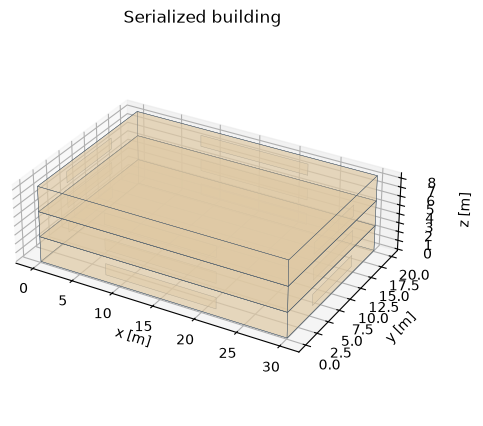

In [4]:
import subprocess
for args in [["schema"],["validate",str(path)]]:
    proc=subprocess.run([sys.executable,"-m","epsm_core.cli",*args],capture_output=True,text=True,check=True)
    print(proc.stdout[:500])
table([{ "artifact":p.name,"bytes":p.stat().st_size} for p in OUT.iterdir()])
preview(b,"Serialized building")

## Interpretation and next experiment

Archive immutable specifications alongside simulation results. A human-readable identifier alone is not enough to establish which inputs produced a result.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.